<a href="https://colab.research.google.com/github/LamaAbdulal/AISE4010_Project/blob/main/standard_RNN_demo2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# For Stage 2: RNN and TCN models.

# 1<sup>st</sup>: Standard RNN

Standard RNN is the most basic version of an RNN. The output at each time step depends on both the current input and the hidden state from the previous time step. Unfortunetly, it can suffer from vanishing gradients problem. This mean it can be difficult for them to learn long-term dependencies. Therefore, standard RNNs excel in predicting tasks with short-term dependencies. This code attempts to train an RNN model for predicting bike counts 1 day into the future based on 7 day history.



In [ ]:
# import libraries
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mlp
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
import plotly.express as px

In [ ]:
#load dataset with sampling frequency of each day
df = pd.read_csv('day.csv')

df = df.rename(columns={'dteday': 'date'})
df['date'] = pd.to_datetime(df['date'])
df = df.set_index('date') #make date the new index for this to be a true time series
df.head()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
date,,,,,,,,,,,,,,,
2011-01-01,1,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
2011-01-02,2,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2011-01-03,3,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
2011-01-04,4,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
2011-01-05,5,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [ ]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# first 70% of time series is training - can be used to create scaler object
train_limit = int(len(df) * 0.70)

# Apply a log transform to the cnt, casual, registered variables to remove non-stationarity
log_cnt = np.log(df['cnt'])
log_casual = np.log(df['casual'])
log_registered = np.log(df['registered'])

# Initialize Scalers
scaler_cnt = MinMaxScaler()
scaler_casual = MinMaxScaler()
scaler_registered = MinMaxScaler()

# Fit scalers on training portion only, then transform entire series
scaler_cnt.fit(log_cnt.values[:train_limit].reshape(-1, 1))
scaled_log_cnt = scaler_cnt.transform(log_cnt.values.reshape(-1, 1))

scaler_casual.fit(log_casual.values[:train_limit].reshape(-1, 1))
scaled_log_casual = scaler_casual.transform(log_casual.values.reshape(-1, 1))

scaler_registered.fit(log_registered.values[:train_limit].reshape(-1, 1))
scaled_log_registered = scaler_registered.transform(log_registered.values.reshape(-1, 1))

In [ ]:
# Initialize Scalers for temp and atemp
scaler_temp = MinMaxScaler()
scaler_atemp = MinMaxScaler()

# Fit on training portion only, then transform
scaler_temp.fit(df['temp'].values[:train_limit].reshape(-1, 1))
scaled_temp = scaler_temp.transform(df['temp'].values.reshape(-1, 1))

scaler_atemp.fit(df['atemp'].values[:train_limit].reshape(-1, 1))
scaled_atemp = scaler_atemp.transform(df['atemp'].values.reshape(-1, 1))

In [ ]:
# Initialize Scalers for windspeed and hum
scaler_windspeed = MinMaxScaler()
scaler_hum = MinMaxScaler()

# Fit on training portion only, then transform
scaler_windspeed.fit(df['windspeed'].values[:train_limit].reshape(-1, 1))
scaled_windspeed = scaler_windspeed.transform(df['windspeed'].values.reshape(-1, 1))

scaler_hum.fit(df['hum'].values[:train_limit].reshape(-1, 1))
scaled_hum = scaler_hum.transform(df['hum'].values.reshape(-1, 1))

Goal: read the last 7 days and forecast the next day. This type of simple RNN is


*   many-to-one
*   unidirectional



Recreate supervised learning dataset with X and y (just like from demo 1)

1.   combine all 7 scaled variables into 2D numpy array
2.   split the array into sliding windows X(N,7,7) y(N,1,7)




In [ ]:
# 1.
import numpy as np

# Creating a 2D numpy array by making each row (time step) have all 7 parallel scaled features (731, 7)
# Note: ensuring all features are reshaped properly to 1D before column_stack
multivariate_data = np.column_stack([
    scaled_log_cnt.flatten(),
    scaled_log_casual.flatten(),
    scaled_log_registered.flatten(),
    scaled_temp.flatten(),
    scaled_atemp.flatten(),
    scaled_windspeed.flatten(),
    scaled_hum.flatten()
])

print("Combined multivariate data shape:", multivariate_data.shape)

Combined multivariate data shape: (731, 7)


In [ ]:
# 2. Define a function to split our parallel sequences into sliding window samples predicting all variables
def split_multivariate_sequences(sequences, lookback, horizon=1):
    X, y = [], []
    for i in range(len(sequences)):
        # find the end of this pattern
        end_ix = i + lookback
        out_end_ix = end_ix + horizon - 1
        # check if we are beyond the dataset
        if out_end_ix >= len(sequences):
            break
        # gather input (past history) and output (future values for all 7 variables)
        seq_x, seq_y = sequences[i:end_ix, :], sequences[end_ix:out_end_ix + 1, :]
        X.append(seq_x)
        y.append(seq_y)
    return np.array(X), np.array(y)

# Define parameters
L = 7  # Lookback window (7 days of history)
h = 1  # Horizon (predicting next day)

# 3. Create the dataset
X, y = split_multivariate_sequences(multivariate_data, lookback=L, horizon=h)

print("X shape (samples, lookback, features):", X.shape)
print("y shape (samples, horizon, features):", y.shape)

X shape (samples, lookback, features): (724, 7, 7)
y shape (samples, horizon, features): (724, 1, 7)


In [ ]:
# Calculate the split indices
total_samples = len(X)
train_end = int(total_samples * 0.70)       # 70% for Training
val_end = int(total_samples * 0.85)         # 15% for Validation, remaining 15% for Test

# Split inputs (X)
X_train, X_val, X_test = X[:train_end], X[train_end:val_end], X[val_end:]

# Split targets (y)
y_train, y_val, y_test = y[:train_end], y[train_end:val_end], y[val_end:]

print(f"Total sliding window samples: {total_samples}")
print(f"Train set shape:      X={X_train.shape}, y={y_train.shape}")
print(f"Validation set shape: X={X_val.shape}, y={y_val.shape}")
print(f"Test set shape:       X={X_test.shape}, y={y_test.shape}")

Total sliding window samples: 724
Train set shape:      X=(506, 7, 7), y=(506, 1, 7)
Validation set shape: X=(109, 7, 7), y=(109, 1, 7)
Test set shape:       X=(109, 7, 7), y=(109, 1, 7)


# Standard RNN Model

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Reshape

# Get parameters from data shapes
n_steps = X_train.shape[1] # 7 days lookback
n_features = X_train.shape[2] # 7 features per input sample
output_dim = y_train.shape[2] # 7 features to predict (target)
horizon = y_train.shape[1] # horizon 1 day

# Standard RNN model definition
model = Sequential([
    SimpleRNN(64, activation='tanh', input_shape=(n_steps, n_features)), #hidden state vector is size 64
    Dense(horizon * output_dim), #fully connected layer at end
    Reshape((horizon, output_dim)) #match the shape of targets in y_train
])

#used tanh activation function because sigmoid is prone to vanishing gradient problem. Additionally, ReLu can cause exploding gradients.

# Compile the model
model.compile(optimizer='adam', loss='mse', metrics=['mae'])

model.summary()

# Train the model
history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=16,
    validation_data=(X_val, y_val),
    verbose=1
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7)              │           455 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 1, 7)           │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,063 (19.78 KB)

 Trainable params: 5,063 (19.78 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 0.1108 - mae: 0.2348 - val_loss: 0.0454 - val_mae: 0.1689
Epoch 2/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0293 - mae: 0.1320 - val_loss: 0.0195 - val_mae: 0.1150
Epoch 3/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0228 - mae: 0.1164 - val_loss: 0.0105 - val_mae: 0.0820
Epoch 4/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0203 - mae: 0.1087 - val_loss: 0.0098 - val_mae: 0.0769
Epoch 5/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0188 - mae: 0.1047 - val_loss: 0.0129 - val_mae: 0.0926
Epoch 6/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0177 - mae: 0.1015 - val_loss: 0.0094 - val_mae: 0.0781
Epoch 7/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0165 - mae: 0.0975 - val_loss: 0.0107 - val_mae: 0.0830
Epoch 8/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0158 - mae: 0.0949 - val_loss: 0.0094 - val_mae: 0.0773
Epoch 9/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0160 - mae:

In [ ]:
!pip install keras-tuner -q

# Hyperparameter Tuning
The hyperparameters include number of neurons in simple RNN layer, learning rate, dropout rate, and batch size. Rather than doing a manual grid search, I used keras' tuner.

In [ ]:
!pip install -q keras-tuner

import keras_tuner as kt
from tensorflow.keras.layers import Dropout

def build_model(hp):
    model = Sequential()
    # Tune the number of units in the SimpleRNN layer
    hp_units = hp.Int('units', min_value=16, max_value=128, step=16)
    # Tune dropout rate
    hp_dropout = hp.Float('dropout', min_value=0.0, max_value=0.3, step=0.1)

    model.add(SimpleRNN(
        units=hp_units,
        activation='tanh',
        dropout=hp_dropout,
        input_shape=(n_steps, n_features)
    ))

    model.add(Dense(horizon * output_dim))
    model.add(Reshape((horizon, output_dim)))

    # Tune the learning rate for the optimizer
    hp_learning_rate = hp.Choice('learning_rate', values=[1e-2, 1e-3, 1e-4])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=hp_learning_rate),
        loss='mse',
        metrics=['mae']
    )
    return model

# Set up Random Search Tuner
tuner = kt.RandomSearch(
    build_model,
    objective='val_loss',
    max_trials=10,
    executions_per_trial=1,
    directory='rnn_tuning',
    project_name='bike_sharing_v2'
)

# Search for the best hyperparameters, including tuning the batch size here!
tuner.search(
    X_train, y_train,
    epochs=20,
    validation_data=(X_val, y_val),
    batch_size=tuner.oracle.hyperparameters.Choice('batch_size', values=[16, 32, 64]),
    verbose=1
)

# Get the best hyperparameters
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print(f"""
Optimal RNN units: {best_hps.get('units')}
Optimal dropout rate: {best_hps.get('dropout')}
Optimal learning rate: {best_hps.get('learning_rate')}
Optimal batch size: {best_hps.get('batch_size')}
""")

Trial 10 Complete [00h 00m 07s]
val_loss: 0.010237513110041618

Best val_loss So Far: 0.005968986079096794
Total elapsed time: 00h 01m 16s

Optimal RNN units: 128
Optimal dropout rate: 0.0
Optimal learning rate: 0.01
Optimal batch size: 32



# Results of Best Model


In [ ]:
# Build the final model with the optimal hyperparameters
best_model = tuner.hypermodel.build(best_hps)

# Fit the final model on the training data
history = best_model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=best_hps.get('batch_size'),
    validation_data=(X_val, y_val),
    verbose=1
)


Epoch 1/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 0.2956 - mae: 0.3641 - val_loss: 0.0856 - val_mae: 0.2432
Epoch 2/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0469 - mae: 0.1722 - val_loss: 0.0321 - val_mae: 0.1497
Epoch 3/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0309 - mae: 0.1403 - val_loss: 0.0234 - val_mae: 0.1289
Epoch 4/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0227 - mae: 0.1170 - val_loss: 0.0138 - val_mae: 0.0901
Epoch 5/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0212 - mae: 0.1127 - val_loss: 0.0092 - val_mae: 0.0757
Epoch 6/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0179 - mae: 0.1026 - val_loss: 0.0076 - val_mae: 0.0655
Epoch 7/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0183 - mae: 0.1048 - val_loss: 0.0116 - val_mae: 0.0898
Epoch 8/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0176 - mae: 0.1023 - val_loss: 0.0080 - val_mae: 0.0680
Epoch 9/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0

In [ ]:
# Evaluate the final model on test data
test_loss, test_mae = best_model.evaluate(X_test, y_test, verbose=1)
print(f"Test MSE (Loss): {test_loss:.5f}")
print(f"Test MAE: {test_mae:.5f}")


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0264 - mae: 0.0997
Test MSE (Loss): 0.02635
Test MAE: 0.09974


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step


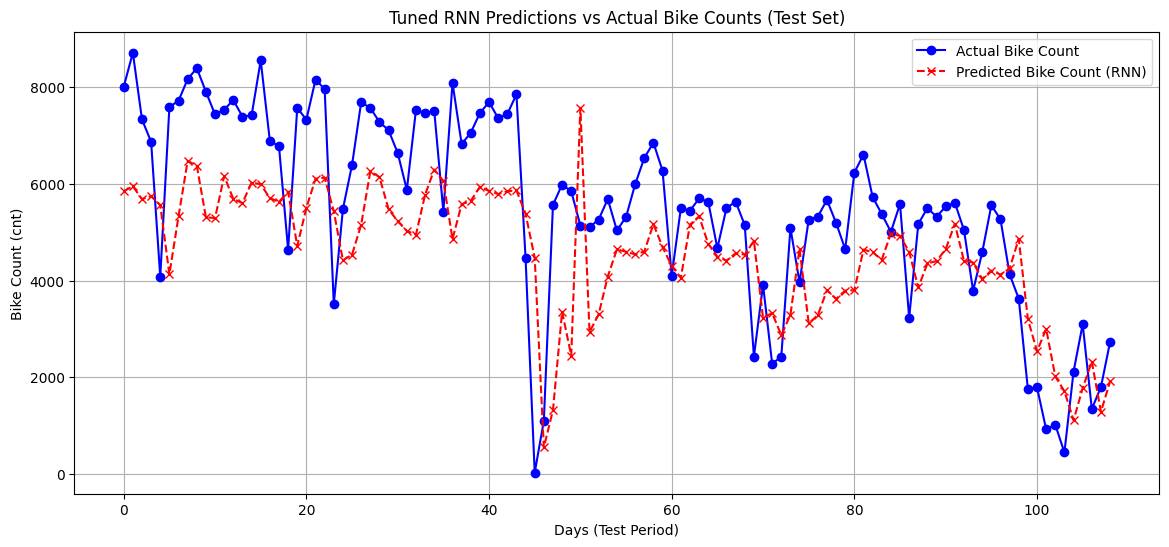

In [ ]:
# 1. Predict on test set
predictions = best_model.predict(X_test)

# 2. Extract predictions and actuals for the 'cnt' variable (index 0 in our feature array)
# Our target arrays have shape (samples, 1, 7)
pred_cnt_scaled = predictions[:, 0, 0].reshape(-1, 1)
actual_cnt_scaled = y_test[:, 0, 0].reshape(-1, 1)

# 3. Inverse transform from MinMax scaling
pred_cnt_log = scaler_cnt.inverse_transform(pred_cnt_scaled)
actual_cnt_log = scaler_cnt.inverse_transform(actual_cnt_scaled)

# 4. Inverse transform from Log scaling
pred_cnt = np.exp(pred_cnt_log)
actual_cnt = np.exp(actual_cnt_log)

# 5. Plot actuals vs predictions
plt.figure(figsize=(14, 6))
plt.plot(actual_cnt, label='Actual Bike Count', color='blue', marker='o')
plt.plot(pred_cnt, label='Predicted Bike Count (RNN)', color='red', linestyle='--', marker='x')
plt.title('Tuned RNN Predictions vs Actual Bike Counts (Test Set)')
plt.xlabel('Days (Test Period)')
plt.ylabel('Bike Count (cnt)')
plt.legend()
plt.grid(True)
plt.show()

# Conclusion
Remarkably good at capturing cyclic nature of bike count. Better MAE test results than all models from demo 1 except naive baseline. The naive baseline from demo 1 got MAE of 0.098 and this simple RNN has MAE test result of 0.09974.

----------------------------------------------------------------------------------




# 2<sup>nd</sup>: TCN

In [18]:
from tensorflow import keras
from tensorflow.keras import layers
import time

In [19]:
#Defining required inputs first:

KERNEL_SIZE = 5           # TCN kernel size k. Assume 5.
DILATIONS = [1, 2, 4, 8, 16]    # TCN: one residual block per dilation

FILTERS = 8              # TCN filters per convolution. Assume 8.
RANDOM_SEED = 303        #Assumed similar to tutorial.
WINDOW = 7               #Lookback of 7 days in the past.
DROPOUT = 0.1            #Assume for now.

In [26]:
# Step 1: Build the TCN model with correct multivariate input dimensions

keras.utils.set_random_seed(RANDOM_SEED)

n_features = X_train.shape[2]
inputs = keras.Input(shape=(WINDOW, n_features))

def residual_block(x, dilation, name):
  shortcut = x if x.shape[-1] == FILTERS else layers.Conv1D(FILTERS, 1)(x)              #So, when the size of channels differs, use 1x1 convolution.
  for _ in range(2):
    x = layers.Conv1D(FILTERS, KERNEL_SIZE, padding='causal', dilation_rate=dilation)(x) #Making sure convolution is causal to avoid using future data.
    x = layers.LayerNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(DROPOUT)(x)
  return layers.Activation('relu', name=name)(layers.Add()([shortcut, x]))

x = inputs
for i, d in enumerate(DILATIONS, start=1):
  x = residual_block(x, d, name=f'block{i}')

# Match output to predicting 1 target variable
outputs = layers.Dense(1)(x[:, -1, :])                                                #The newest time step will be the forecast.
tcn = keras.Model(inputs, outputs, name='tcn')

print(f'TCN: {len(DILATIONS)} residual blocks, dilations {DILATIONS}, {tcn.count_params():,} trainable parameters')

TCN: 5 residual blocks, dilations [1, 2, 4, 8, 16], 3,473 trainable parameters


In [27]:
#Step 2: Build the receptive field (the area that the convolution
#filter will be applied to):
receptive_field = 1 + 2 * (KERNEL_SIZE - 1) * sum(DILATIONS)

print(f'Receptive field r = {receptive_field} days')
print(f'Window = {WINDOW} days')
print(f'Does the receptive field cover the window? {receptive_field >= WINDOW}')

Receptive field r = 249 days
Window = 7 days
Does the receptive field cover the window? True


Epoch 1/60
16/16 ━━━━━━━━━━━━━━━━━━━━ 10s 57ms/step - loss: 0.0178 - val_loss: 0.0095
Epoch 2/60
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0153 - val_loss: 0.0080
Epoch 3/60
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0161 - val_loss: 0.0099
Epoch 4/60
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0149 - val_loss: 0.0068
Epoch 5/60
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0156 - val_loss: 0.0067
Epoch 6/60
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0149 - val_loss: 0.0057
Epoch 7/60
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0150 - val_loss: 0.0068
Epoch 8/60
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0149 - val_loss: 0.0055
Epoch 9/60
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0136 - val_loss: 0.0040
Epoch 10/60
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0147 - val_loss: 0.0105
Epoch 11/60
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0140 - val_loss: 0.0058
Epoch 12/60
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.

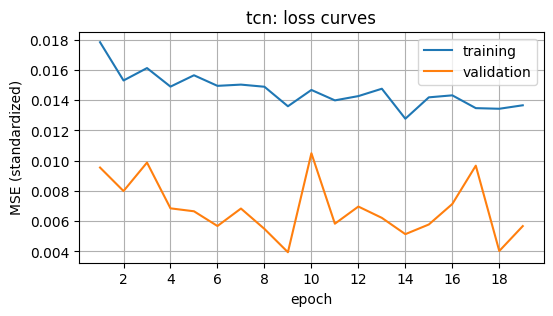

In [32]:
# Step 3: Train the TCN model
import time

def train(model, learning_rate):
  keras.utils.set_random_seed(RANDOM_SEED)
  model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate), loss='mse')
  stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
  start = time.time()

  # Match targets shape to the model output
  y_train_cnt = y_train[:, 0, 0]
  y_val_cnt = y_val[:, 0, 0]

  history = model.fit(
      X_train, y_train_cnt,
      validation_data=(X_val, y_val_cnt),
      epochs=60,
      batch_size=32,
      callbacks=[stop],
      verbose=1
  )
  seconds = time.time() - start

  print(f"{model.name}: {len(history.history['loss'])} epochs in {seconds:.0f} s, "
        f"best epoch {np.argmin(history.history['val_loss']) + 1}")

  plt.figure(figsize=(6, 3))
  epochs = np.arange(1, len(history.history['loss']) + 1)
  plt.plot(epochs, history.history['loss'], label='training')
  plt.plot(epochs, history.history['val_loss'], label='validation')
  plt.title(f'{model.name}: loss curves')
  plt.xlabel('epoch')
  plt.ylabel('MSE (standardized)')
  plt.gca().xaxis.set_major_locator(plt.MaxNLocator(integer=True))
  plt.legend()
  plt.grid(True)
  plt.show()
  return seconds

train_seconds = {'TCN': train(tcn, learning_rate=1e-3)}

### The training and validation loss curves are not good, so need to stabilize the training process by:
- adjusting the dilations list to better fit our 7-day window, since the dilations are too much for just 7 days
- maybe try reducing the learning rate to avoid not converging (jumping away from minimum point).

Epoch 1/60
16/16 ━━━━━━━━━━━━━━━━━━━━ 6s 39ms/step - loss: 26.8226 - val_loss: 18.4051
Epoch 2/60
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 12.0720 - val_loss: 4.9350
Epoch 3/60
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 3.7619 - val_loss: 0.5754
Epoch 4/60
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 1.1220 - val_loss: 0.0311
Epoch 5/60
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.5862 - val_loss: 0.0292
Epoch 6/60
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.5719 - val_loss: 0.0256
Epoch 7/60
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.4383 - val_loss: 0.0200
Epoch 8/60
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.4037 - val_loss: 0.0216
Epoch 9/60
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.3747 - val_loss: 0.0216
Epoch 10/60
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.4310 - val_loss: 0.0188
Epoch 11/60
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.3735 - val_loss: 0.0184
Epoch 12/60
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 

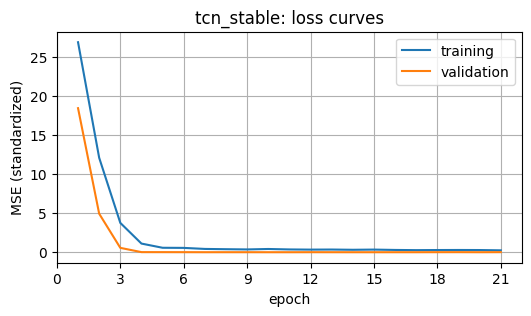

In [33]:
'''
def reset_seeds(seed_value):
    # Set seed for reproducible results across all backends
    np.random.seed(seed_value)
    random.seed(seed_value)
    tf.random.set_seed(seed_value)
    keras.utils.set_random_seed(seed_value)

# 1. Apply Seeding
reset_seeds(RANDOM_SEED)
'''

# 2. Define shorter dilations since WINDOW is only 7
STABLE_DILATIONS = [1, 2, 4]

# 3. Build TCN Model with optimal dimensions
n_features = X_train.shape[2]
inputs_stable = keras.Input(shape=(WINDOW, n_features))

def residual_block_stable(x, dilation, name):
  shortcut = x if x.shape[-1] == FILTERS else layers.Conv1D(FILTERS, 1)(x)
  for _ in range(2):
    x = layers.Conv1D(FILTERS, KERNEL_SIZE, padding='causal', dilation_rate=dilation)(x)
    x = layers.LayerNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(DROPOUT)(x)
  return layers.Activation('relu', name=name)(layers.Add()([shortcut, x]))

x_s = inputs_stable
for i, d_s in enumerate(STABLE_DILATIONS, start=1):
  x_s = residual_block_stable(x_s, d_s, name=f'stable_block{i}')

outputs_stable = layers.Dense(1)(x_s[:, -1, :])
tcn_stable = keras.Model(inputs_stable, outputs_stable, name='tcn_stable')

# 4. Train with a lower, more stable learning rate
train_seconds['TCN_Stable'] = train(tcn_stable, learning_rate=5e-4)

In [36]:
#To confirm if the TCN is indeed causal (does not look at future time values):
PROBE_DAY = 2     #Random day to test if the model is causal.

# Using tcn_stable with its stable dilations
probe = keras.Model(tcn_stable.input, [tcn_stable.get_layer('stable_block1').output, tcn_stable.get_layer(f'stable_block{len(STABLE_DILATIONS)}').output])

# Correctly slice to keep the 3D shape (1, 7, 7)
X_changed = X_test[:1].copy()

X_changed[0, PROBE_DAY, 0] += 1.0     #Added 1 to the probe day.

# Compare the shapes correctly across features
changed_indices = np.where(X_changed != X_test[:1])
print(f'Check: only day {PROBE_DAY} was changed ->', np.all(changed_indices[1] == PROBE_DAY))

before, after = probe.predict(X_test[:1], verbose=0), probe.predict(X_changed, verbose=0)

for name, b, a in zip(['block 1', f'block {len(STABLE_DILATIONS)}'], before, after):
    steps = np.where(np.abs(a - b)[0].max(axis=-1) > 1e-6)[0]                    # time steps whose output changed
    if len(steps) == 0:
      print(f'{name}: no time step changed');
      continue
    print(f'{name}: {len(steps)} time steps changed, from step {steps.min()} to step {steps.max()}')
    print(f'    Check: causal, nothing before step {PROBE_DAY} changed --> {steps.min() >= PROBE_DAY}')

Check: only day 2 was changed -> True
block 1: 5 time steps changed, from step 2 to step 6
    Check: causal, nothing before step 2 changed --> True
block 3: 5 time steps changed, from step 2 to step 6
    Check: causal, nothing before step 2 changed --> True


#### So, the TCN is causal, and this helps us avoid data leakage.

### Hyperparametet tuning for TCN:
Hyperparameters to tune:
- Learning rate
- Kernel size
- Number of filters


In [43]:
from itertools import product
import pandas as pd

learning_rate_range = [1e-3, 1e-2, 0.5e-2]
Kernel_size_range = [3, 5, 7]
number_of_filters_range = [5, 8, 10]

all_results = []

# Loop over configurations and show progress for each model run
for idx, (LR, kernel_size, number_of_filters) in enumerate(product(learning_rate_range, Kernel_size_range, number_of_filters_range), start=1):
    print(f"\n=== Training Configuration {idx}/27: LR={LR}, Kernel Size={kernel_size}, Filters={number_of_filters} ===")
    keras.backend.clear_session()
    keras.utils.set_random_seed(RANDOM_SEED)

    inputs_tune = keras.Input(shape=(WINDOW, n_features))

    def residual_block_tune(x, dilation, name):
        shortcut = x if x.shape[-1] == number_of_filters else layers.Conv1D(number_of_filters, 1)(x) #So, when the size of channels differs, use 1x1 convolution.
        for _ in range(2):
            x = layers.Conv1D(number_of_filters, kernel_size, padding='causal', dilation_rate=dilation)(x) #Making sure convolution is causal to avoid using future data.
            x = layers.LayerNormalization()(x)
            x = layers.Activation('relu')(x)
            x = layers.Dropout(DROPOUT)(x)
        return layers.Activation('relu', name=name)(layers.Add()([shortcut, x]))

    x_tuned = inputs_tune
    for i, d in enumerate(STABLE_DILATIONS, start=1):
        x_tuned = residual_block_tune(x_tuned, d, name=f'block{i}')

    outputs_tune = layers.Dense(1)(x_tuned[:, -1, :])
    model_tune = keras.Model(inputs_tune, outputs_tune)

    model_tune.compile(optimizer=keras.optimizers.Adam(learning_rate=LR), loss='mse')
    stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

    y_train_cnt = y_train[:, 0, 0]
    y_val_cnt = y_val[:, 0, 0]

    # Setting verbose=1 to show epoch progress bar
    history = model_tune.fit(
        X_train, y_train_cnt,
        validation_data=(X_val, y_val_cnt),
        epochs=30,
        batch_size=32,
        callbacks=[stop],
        verbose=1
    )

    best_val_loss = min(history.history['val_loss'])
    all_results.append({
        'learning_rate': LR,
        'kernel_size': kernel_size,
        'filters': number_of_filters,
        'val_loss': best_val_loss
    })
    print(f"Finished Config {idx}/27. Best Val Loss: {best_val_loss:.6f}")

# Create and display the completed grid search results table
full_results_df = pd.DataFrame(all_results)
full_results_df = full_results_df.sort_values(by='val_loss').reset_index(drop=True)
display(full_results_df)


=== Training Configuration 1/27: LR=0.001, Kernel Size=3, Filters=5 ===
Epoch 1/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 7s 47ms/step - loss: 17.5411 - val_loss: 12.1851
Epoch 2/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 7.7923 - val_loss: 5.8351
Epoch 3/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 3.8514 - val_loss: 3.2128
Epoch 4/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 2.1870 - val_loss: 1.7811
Epoch 5/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 1.4155 - val_loss: 1.1017
Epoch 6/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 1.1914 - val_loss: 0.7078
Epoch 7/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 1.0744 - val_loss: 0.4824
Epoch 8/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.8417 - val_loss: 0.3791
Epoch 9/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.8753 - val_loss: 0.3228
Epoch 10/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.7826 - val_loss: 0.2890
Epoch 11/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.7671 - val_l

,learning_rate,kernel_size,filters,val_loss
0,0.005,5,10,0.002647
1,0.010,5,5,0.003594
2,0.010,3,10,0.003619
3,0.010,5,10,0.003820
4,0.010,3,8,0.004080
5,0.001,5,10,0.005106
6,0.001,7,10,0.005167
7,0.005,3,10,0.005450
8,0.005,5,8,0.005716
9,0.005,3,8,0.006563


In [45]:
#The configuration with the best validation loss is:
best_config = full_results_df.iloc[0] #Get the configuration with the lowest validation loss, and because the losses are
                                      #sorted, the 1st row in the table above will be the one with
                                      # lowest validation loss.
print("Optimal Config Found:")
print(best_config)

Optimal Config Found:
learning_rate     0.005000
kernel_size       5.000000
filters          10.000000
val_loss          0.002647
Name: 0, dtype: float64


### Now, with the best hyperparameters, test the model on the test dataset: